# 01 · Entender las visitas y los clientes

**Pregunta de negocio:** ¿qué información disponible antes de una visita ayuda a estimar si terminará en compra?

**Periodo del EDA:** días 1–296 desde la apertura. Es la ventana inicial de entrenamiento propuesta para la validación temporal; las hipótesis que surjan aquí se contrastarán en periodos posteriores. El modelo vigente aún usa otros cortes.

Una fila representa una visita. Se desconocen la fecha calendario de apertura, el producto concreto, la moneda y el significado de algunos códigos demográficos. El periodo de evaluación posterior ya se consultó antes y no es un test virgen.

Este notebook describe los datos; no entrena modelos. Las tablas y figuras se regeneran desde el código del proyecto.

In [1]:
from ferreyros_propension.plotting import apply_theme, save, style_table

apply_theme()

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from ferreyros_propension.data import audit, features, load_data

ROOT = Path.cwd()
if not (ROOT / "Dataset").exists():
    ROOT = ROOT.parent
OUTPUT = ROOT / "outputs"
for folder in ["tables", "figures"]:
    (OUTPUT / folder).mkdir(parents=True, exist_ok=True)
raw = load_data(ROOT / "Dataset/compras_data.csv")
raw = raw.loc[raw.dia_visita.le(296)].copy()

## 1 · ¿Son confiables los datos?

**Nivel:** visita y cliente · **Periodo:** días 1–296.

Revisamos valores faltantes, duplicados y la relación entre las columnas históricas y los eventos previos.

In [2]:
summary, semantics = audit(raw)
display(style_table(summary.to_frame("valor")))
display(style_table(semantics.style.format({"coincidencia": "{:.2%}"})))
profile = pd.DataFrame(
    {
        "tipo": raw.dtypes.astype(str),
        "unicos": raw.nunique(),
        "faltantes": raw.isna().sum(),
        "min": raw.min(),
        "max": raw.max(),
    }
)
display(style_table(profile))
profile.to_csv(OUTPUT / "tables/dictionary_profile.csv")
from ferreyros_propension.data import PROFILE

stability = raw.groupby("id")[PROFILE].nunique().max()
display(style_table(stability.to_frame("max_valores_distintos_por_cliente")))
summary.to_csv(OUTPUT / "tables/audit.csv")
semantics.to_csv(OUTPUT / "tables/history_semantics.csv", index=False)

,valor
filas,25754
clientes,500
columnas,24
faltantes,0
duplicados,0
incoherencia_cantidad,0
incoherencia_marca,0


,variable,hipotesis,coincidencia
0,ultima_marca_comprada,visita_anterior,100.00%
1,ultima_marca_comprada,compra_anterior,42.81%
2,ultima_marca_comprada,evento_actual,69.58%
3,ultima_cantidad_comprada,visita_anterior,82.95%
4,ultima_cantidad_comprada,compra_anterior,25.75%
5,ultima_cantidad_comprada,evento_actual,65.15%
6,ultima_cantidad_comprada,incidencia_visita_anterior,100.00%


,tipo,unicos,faltantes,min,max
id,int64,500,0,200000001.000,200000500.000
dia_visita,int64,296,0,1.000,296.000
incidencia_compra,int64,2,0,0.000,1.000
id_marca,int64,6,0,0.000,5.000
cantidad,int64,16,0,0.000,15.000
ultima_marca_comprada,int64,6,0,0.000,5.000
ultima_cantidad_comprada,int64,2,0,0.000,1.000
precio_marca_1,float64,23,0,1.170,1.590
precio_marca_2,float64,19,0,1.260,1.900
precio_marca_3,float64,12,0,1.870,2.010


,max_valores_distintos_por_cliente
genero,1
estado_civil,1
edad,1
nivel_educacion,1
ingreso_anual,1
ocupacion,1


**Qué revisar:** las coincidencias contrastan el significado real de los campos históricos con distintas hipótesis. Una coincidencia del 100 % describe este periodo; no demuestra su significado fuera de él.

**Decisión:** reconstruir el historial a partir de eventos anteriores y no interpretar automáticamente el cero como dato faltante.

## 2 · ¿Cuántas visitas terminan en compra?
**Nivel: visita · Días 1–296**

,visitas
compra,
0,19630
1,6124


### ¿Cómo cambia el comportamiento entre clientes?
**Nivel: cliente.** Visitas y compras acumuladas en el periodo; conversión = compras / visitas de cada cliente.

,visitas,compras,conversión
Clientes,500.000,500.000,500.000
Promedio,51.508,12.248,0.226
Desviación estándar,12.996,13.896,0.165
Mínimo,31.000,1.000,0.020
Percentil 25,44.000,5.000,0.104
Mediana,50.000,9.000,0.190
Percentil 75,56.000,14.000,0.294
Máximo,167.000,151.000,0.924


### ¿Cómo evoluciona la conversión?
**Nivel: visita.** Compras / visitas en cada bloque de 7 días.

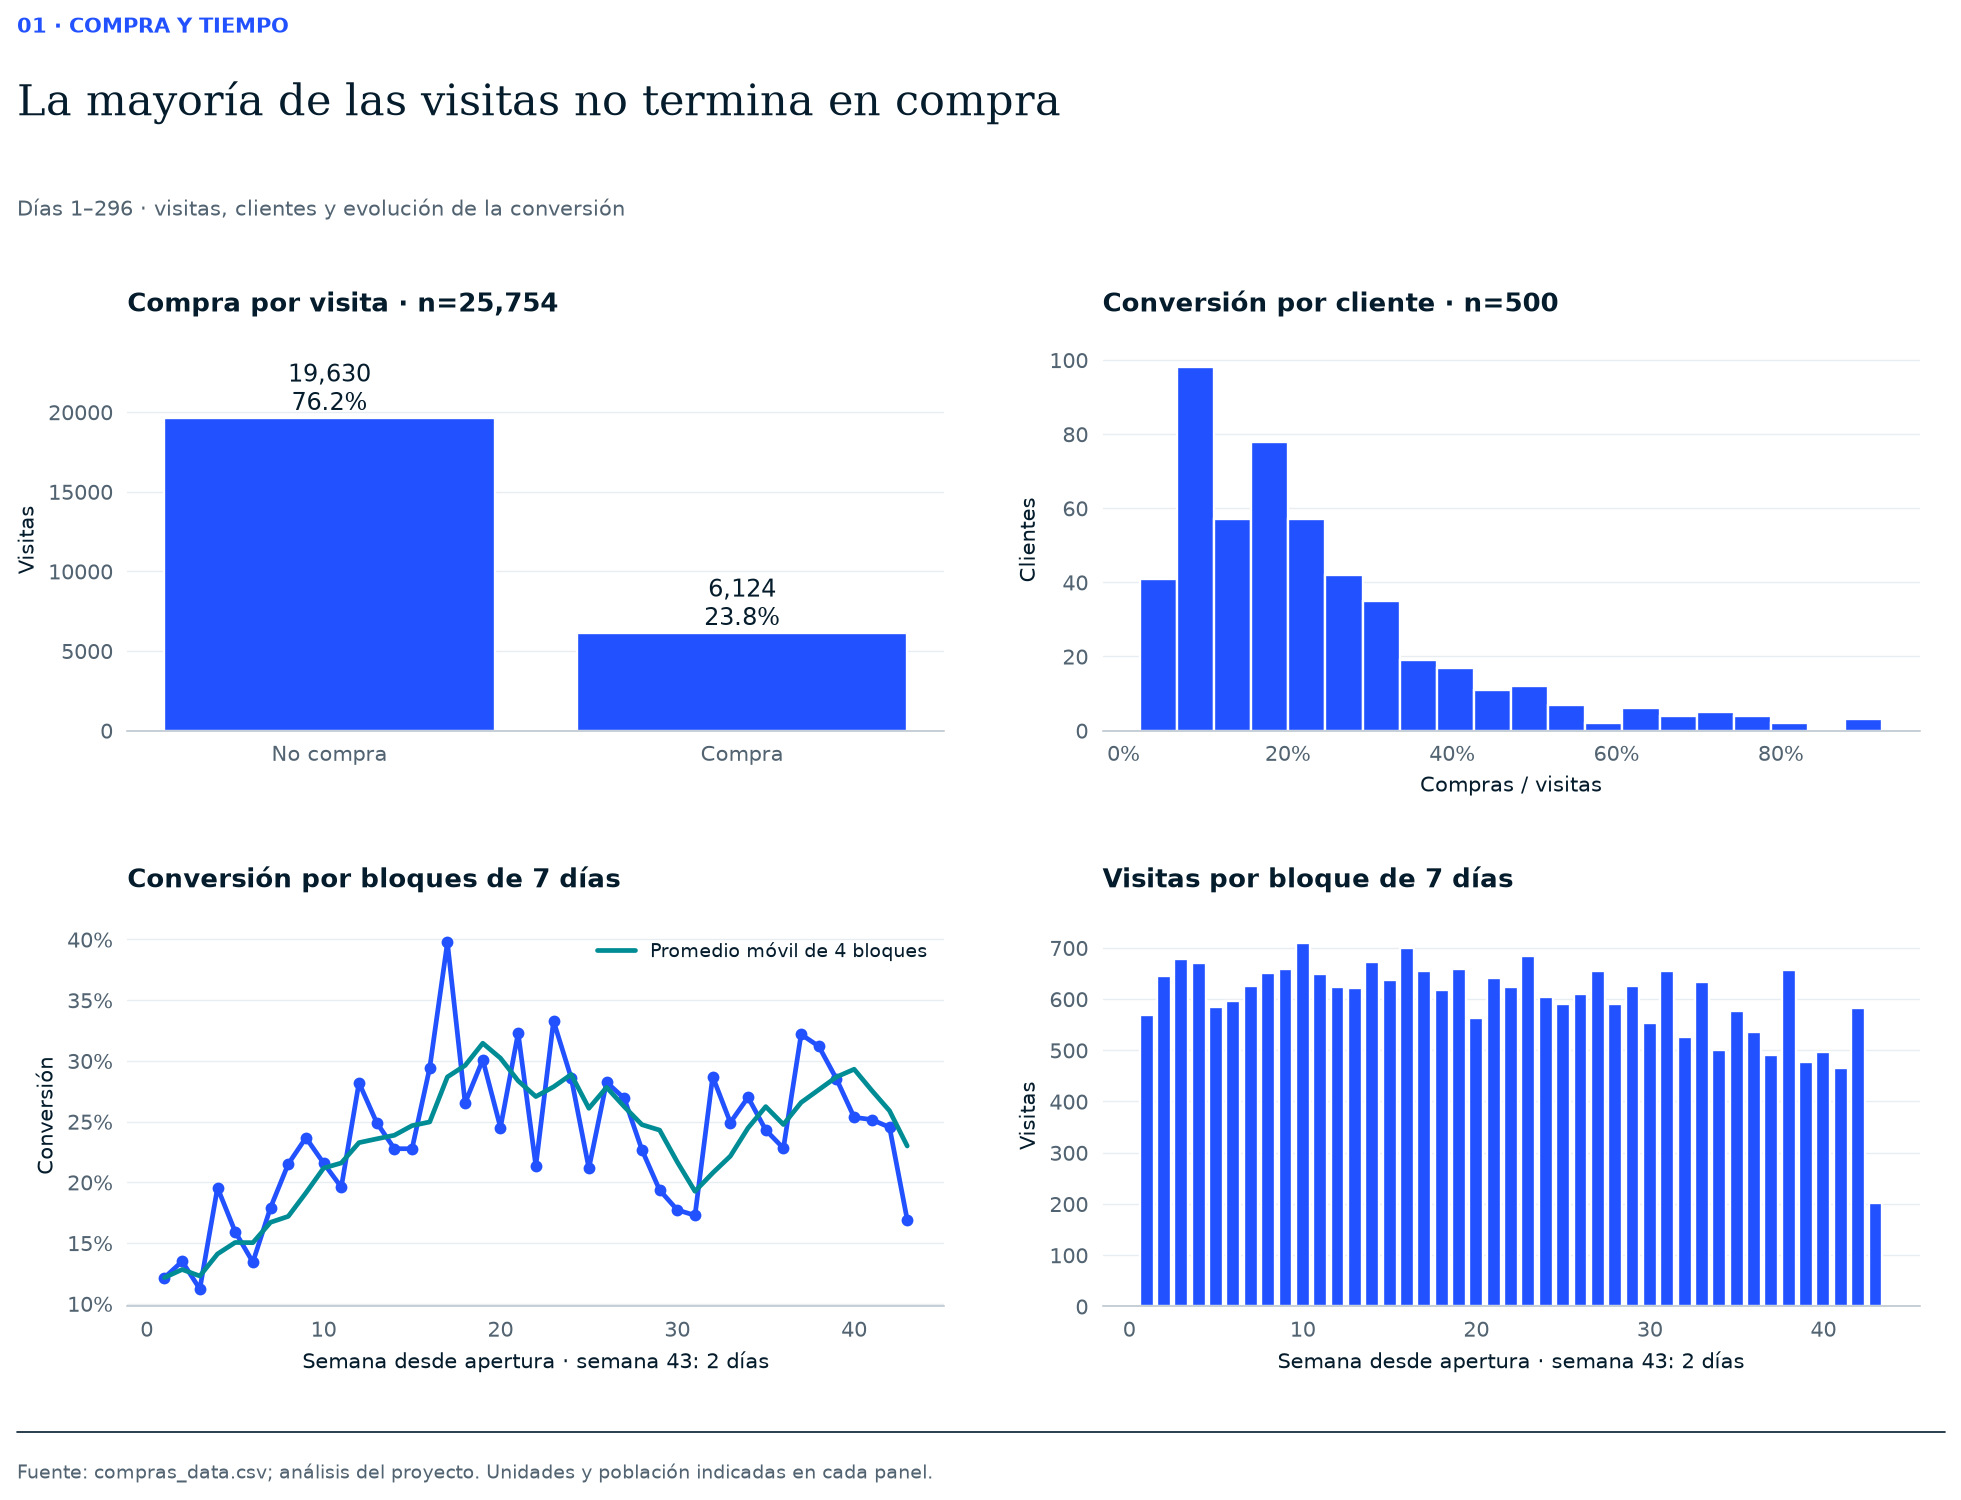

In [3]:
from ferreyros_propension.plotting import eda_figures
from IPython.display import Markdown

customers, periods, transitions = eda_figures(raw, OUTPUT / "figures")
development = raw.loc[raw.dia_visita.le(296)].copy()
clients = development.drop_duplicates("id")

display(Markdown("## 2 · ¿Cuántas visitas terminan en compra?\n**Nivel: visita · Días 1–296**"))
display(style_table(development.incidencia_compra.value_counts().rename_axis("compra").to_frame("visitas")))

display(Markdown("### ¿Cómo cambia el comportamiento entre clientes?\n**Nivel: cliente.** Visitas y compras acumuladas en el periodo; conversión = compras / visitas de cada cliente."))
customer_summary = customers.describe().rename(index={
    "count": "Clientes", "mean": "Promedio", "std": "Desviación estándar",
    "min": "Mínimo", "25%": "Percentil 25", "50%": "Mediana",
    "75%": "Percentil 75", "max": "Máximo",
}).rename(columns={"conversion": "conversión"})
display(style_table(customer_summary.round(3)))

display(Markdown("### ¿Cómo evoluciona la conversión?\n**Nivel: visita.** Compras / visitas en cada bloque de 7 días."))
display(Image(filename=str(OUTPUT / "figures/01_target_tiempo.png")))

La semana 43 contiene solo los días 295–296. La línea de tendencia es un promedio móvil de cuatro bloques; las variaciones no demuestran estacionalidad.

## 3 · ¿Cómo es el perfil de los clientes?
**Nivel: cliente**, salvo los gráficos de conversión, que cuentan visitas.

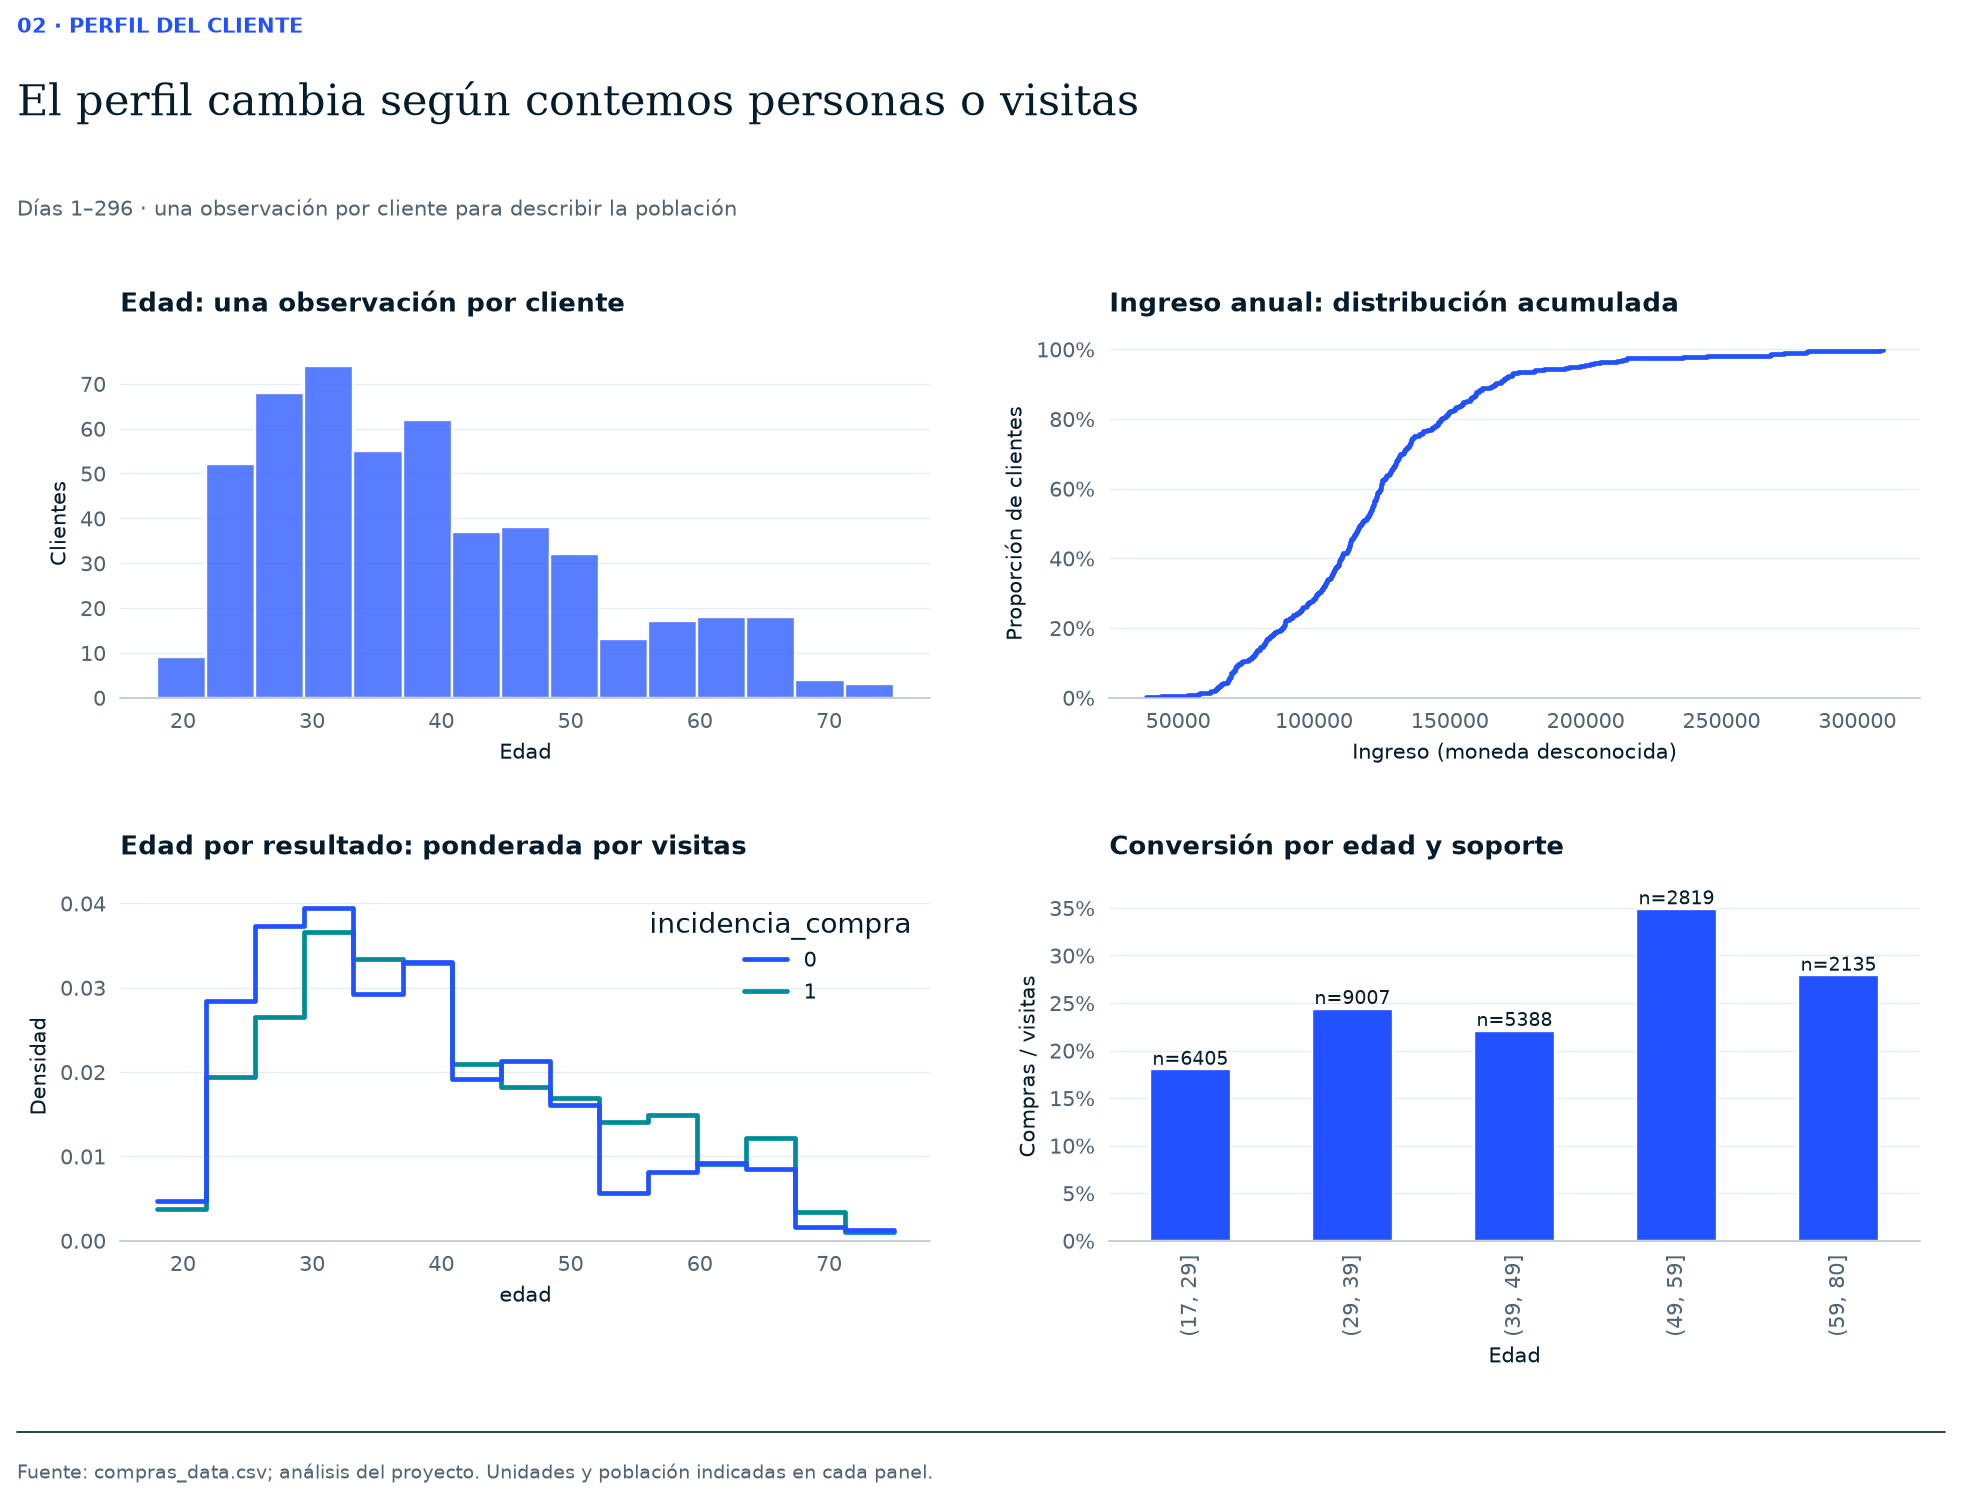

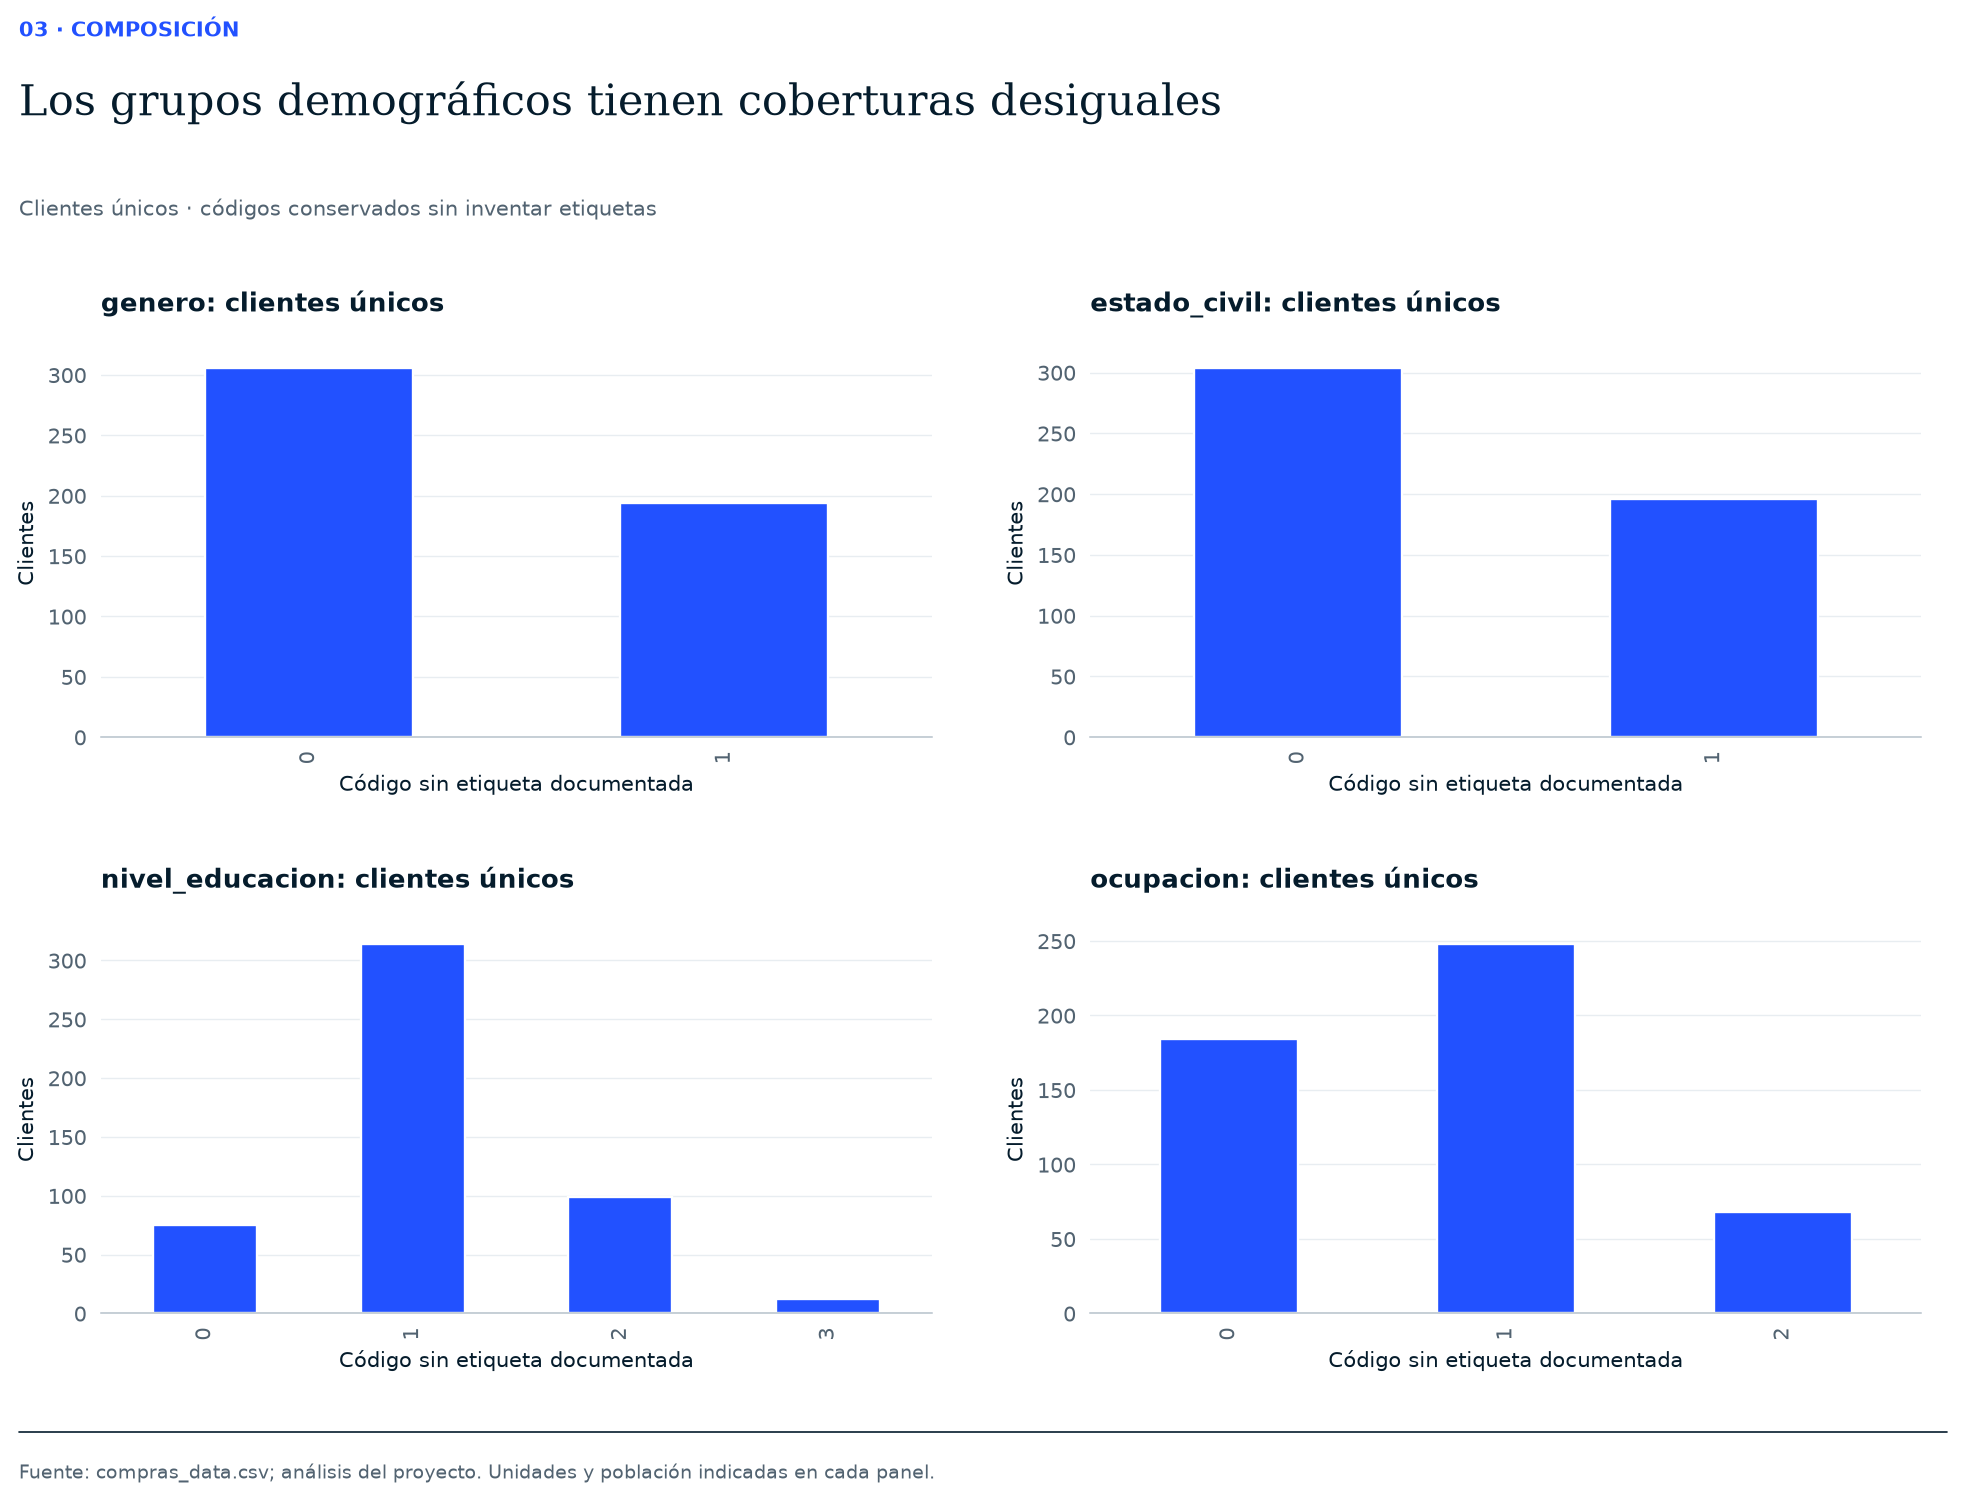

,edad,ingreso_anual
count,500.000,500.000
mean,38.700,121520.200
std,12.200,41062.000
min,18.000,38247.000
10%,25.000,73265.900
50%,36.000,117804.500
90%,57.100,166742.700
99%,68.000,279607.900
max,75.000,309364.000


In [4]:
display(Markdown("## 3 · ¿Cómo es el perfil de los clientes?\n**Nivel: cliente**, salvo los gráficos de conversión, que cuentan visitas."))
display(Image(filename=str(OUTPUT / "figures/02_perfil.png")))
display(Image(filename=str(OUTPUT / "figures/03_demografia.png")))
display(
    style_table(
        clients[["edad", "ingreso_anual"]]
        .describe(percentiles=[0.1, 0.5, 0.9, 0.99])
        .round(1)
    )
)

**Qué buscamos:** diferencias de perfil y de conversión por edad. Los perfiles describen solo los clientes observados; las asociaciones no prueban causalidad.

El siguiente intervalo considera la repetición de visitas mediante remuestreo de clientes.

,edad,clientes,visitas,conversion,low,high
0,"(17, 29]",129,6405,0.180,0.155,0.203
1,"(29, 39]",171,9007,0.244,0.212,0.287
2,"(39, 49]",105,5388,0.221,0.193,0.254
3,"(49, 59]",52,2819,0.349,0.277,0.423
4,"(59, 80]",43,2135,0.279,0.220,0.339


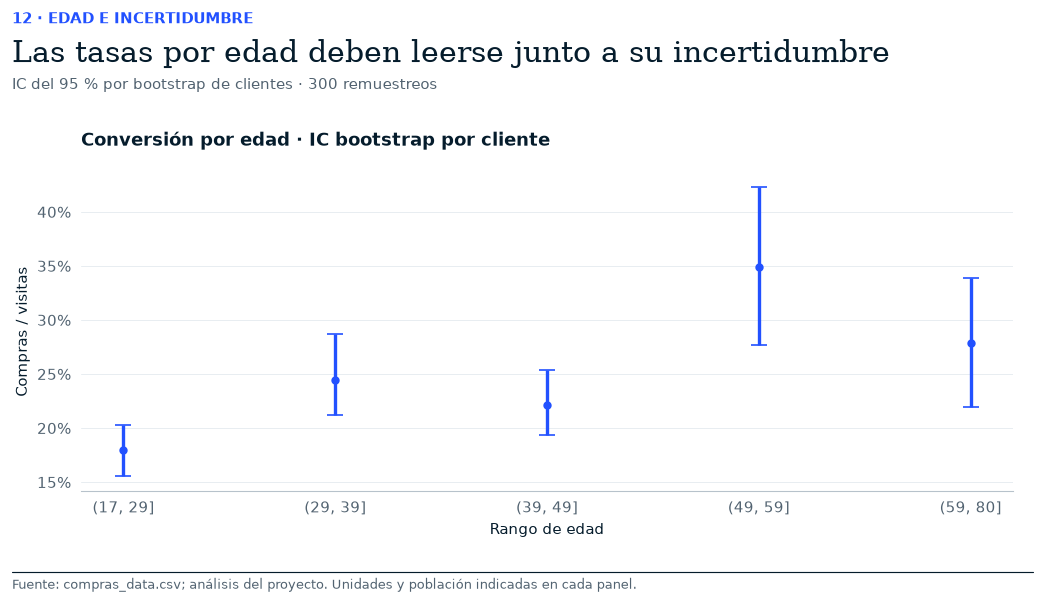

In [5]:
generator = np.random.default_rng(42)
age_data = development.assign(rango=pd.cut(development.edad, [17, 29, 39, 49, 59, 80]))
age_rows = []
for age_range, group in age_data.groupby("rango", observed=True):
    totals = group.groupby("id").incidencia_compra.agg(["sum", "count"])
    draws = generator.integers(0, len(totals), size=(300, len(totals)))
    sums = totals["sum"].to_numpy()[draws].sum(axis=1)
    counts = totals["count"].to_numpy()[draws].sum(axis=1)
    age_rows.append(
        {
            "edad": str(age_range),
            "clientes": len(totals),
            "visitas": len(group),
            "conversion": group.incidencia_compra.mean(),
            "low": np.quantile(sums / counts, 0.025),
            "high": np.quantile(sums / counts, 0.975),
        }
    )
age_summary = pd.DataFrame(age_rows)
display(style_table(age_summary))
figure, axis = plt.subplots(figsize=(9, 4))
axis.errorbar(
    age_summary.edad,
    age_summary.conversion,
    yerr=[
        age_summary.conversion - age_summary.low,
        age_summary.high - age_summary.conversion,
    ],
    fmt="o",
    capsize=5,
)
axis.set(
    title="Conversión por edad · IC bootstrap por cliente",
    xlabel="Rango de edad",
    ylabel="Compras / visitas",
)
save(figure, OUTPUT / "figures", "12_edad_incertidumbre", close=False)
plt.show()

## 4 · ¿Con qué frecuencia compran y qué marcas eligen?
**Nivel: cliente y visita con compra**, según se indica en cada gráfico.

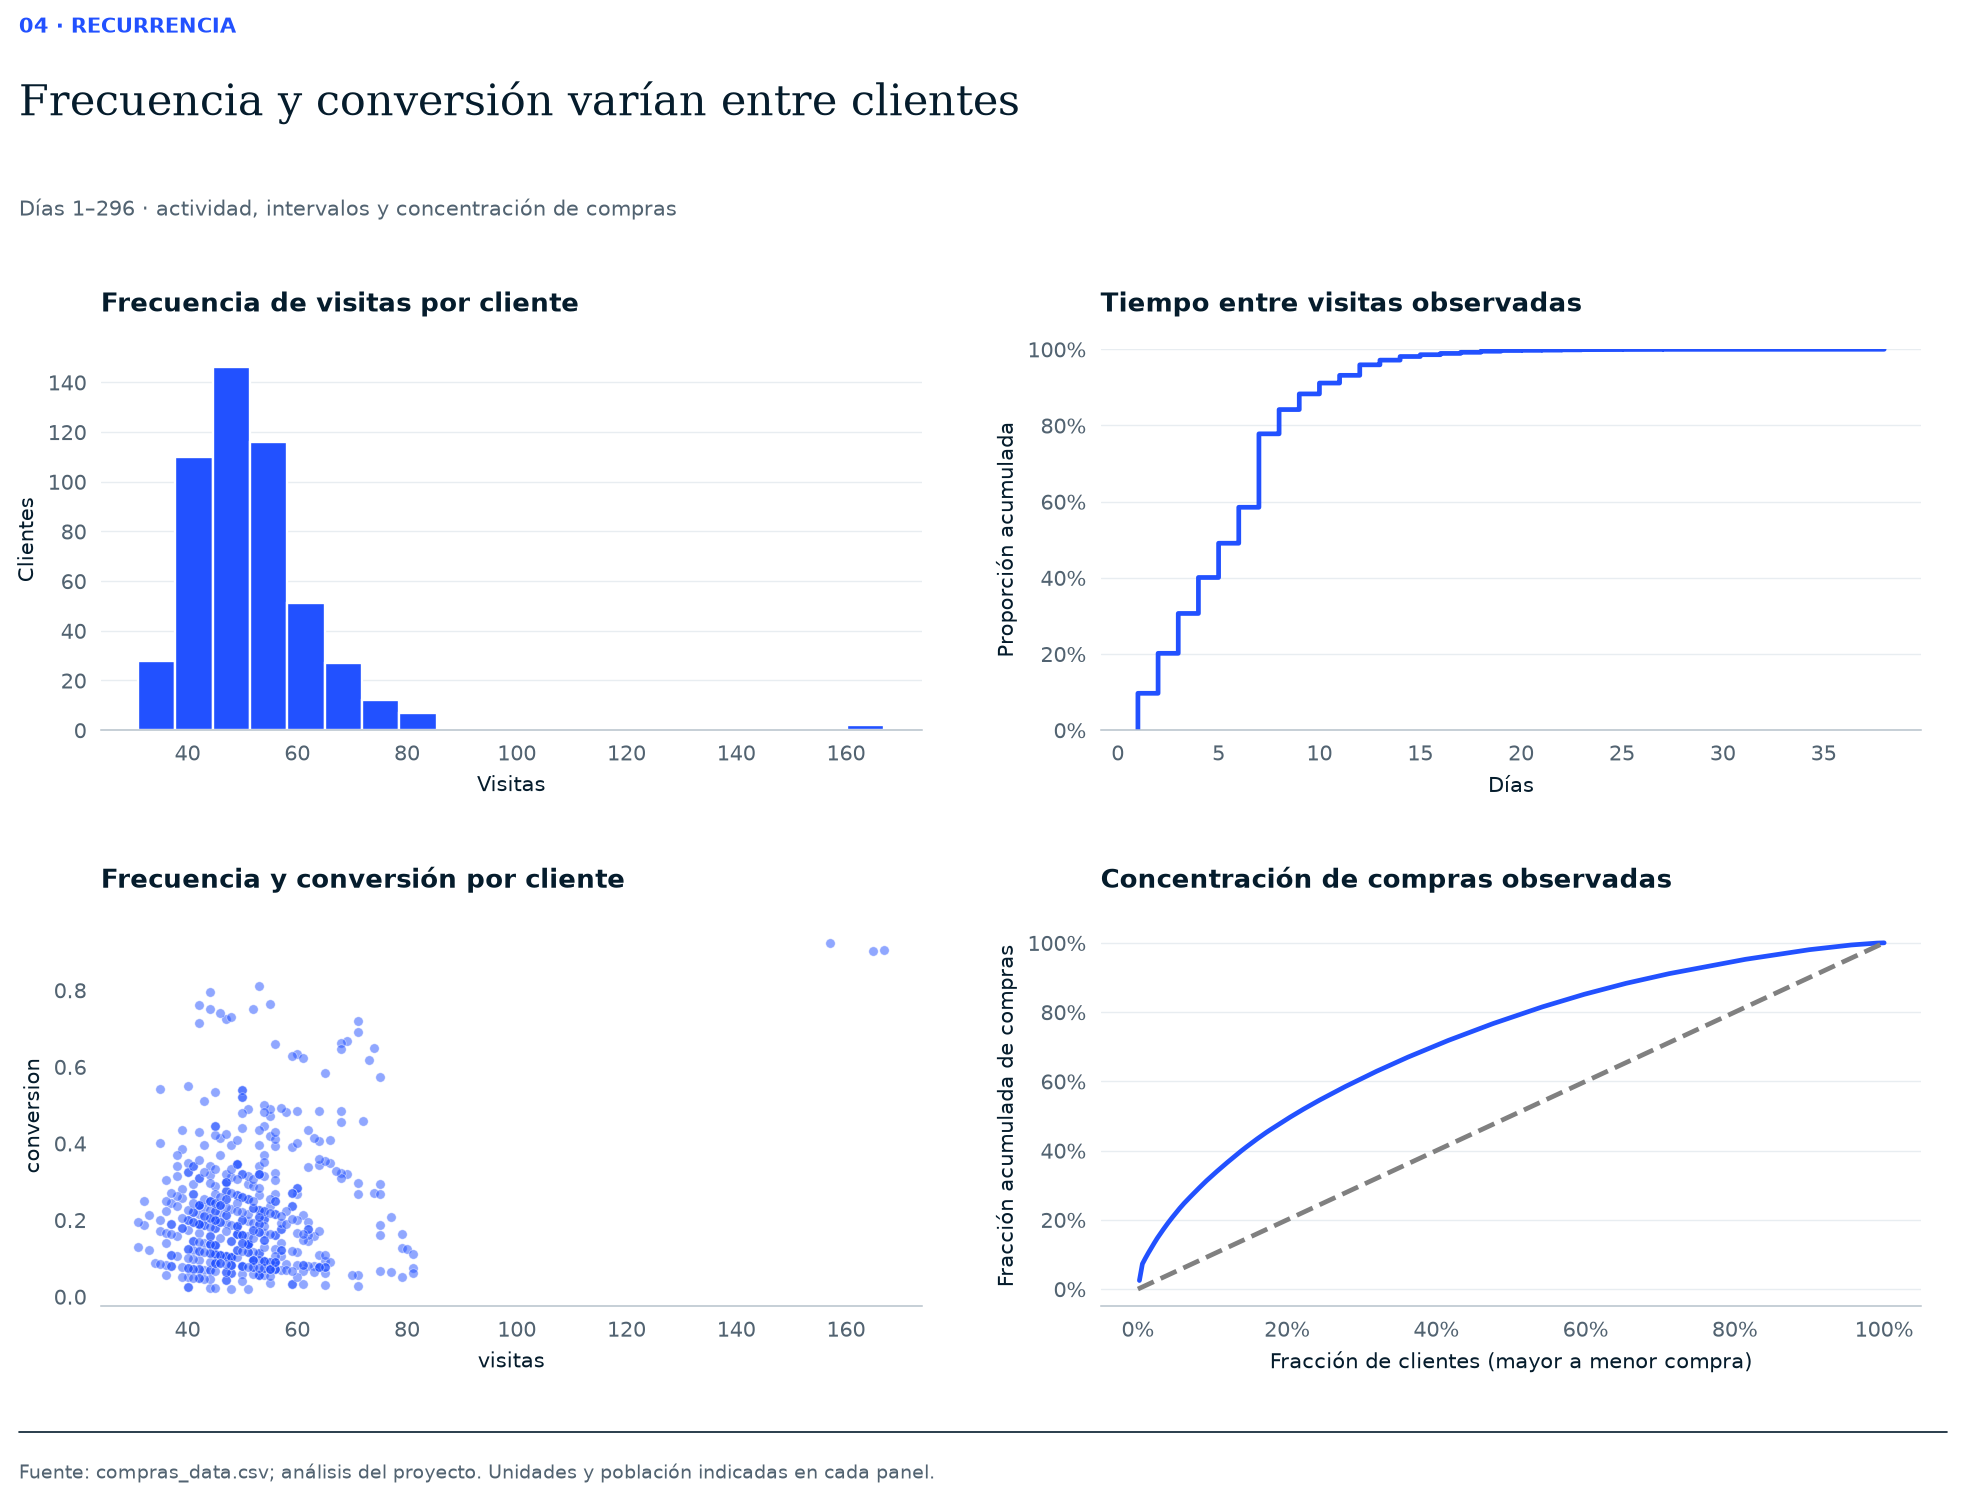

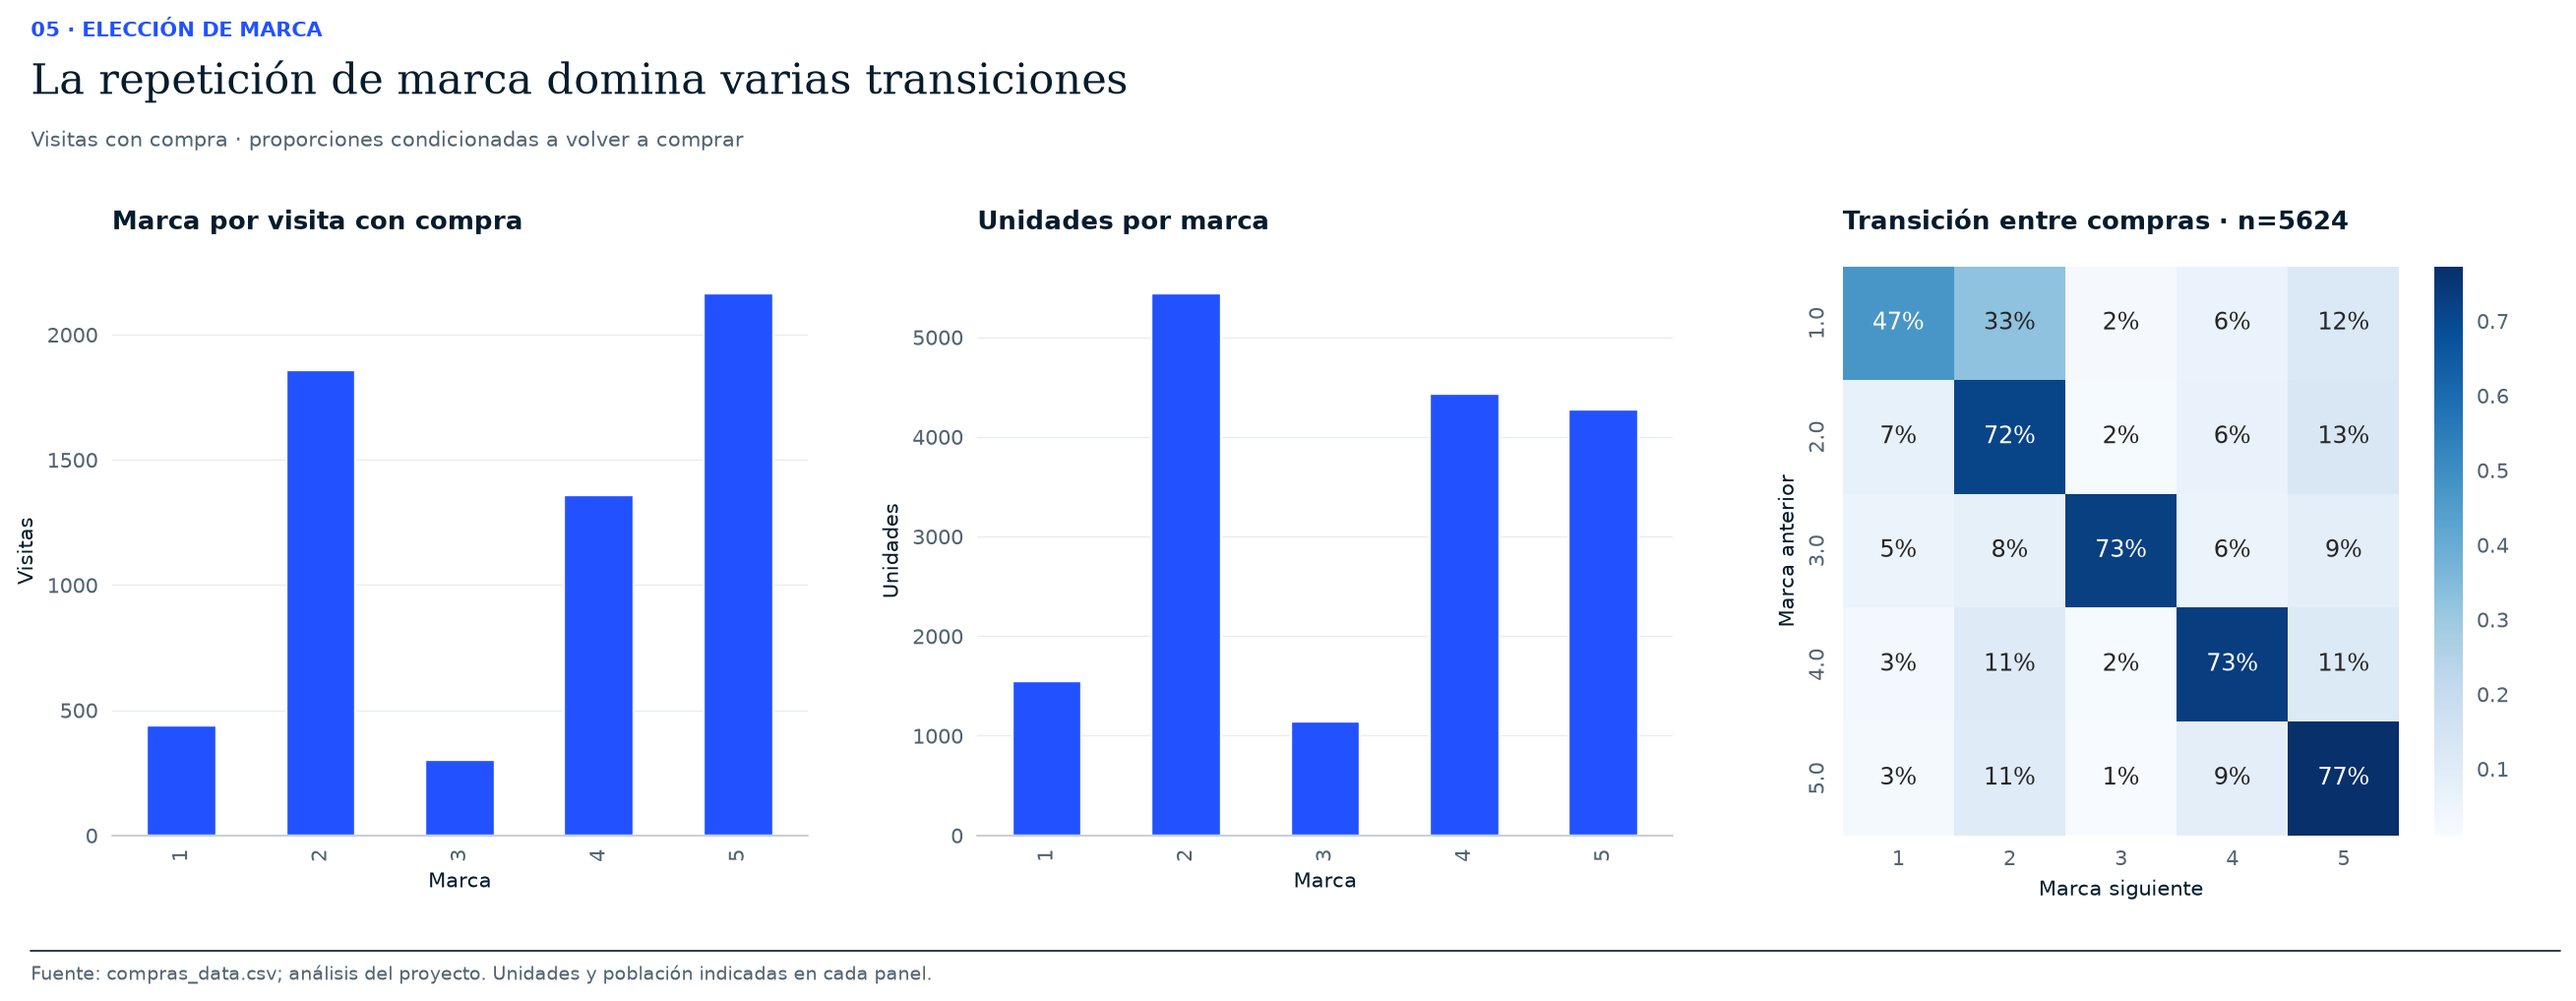

El 20% de clientes con más compras concentra 49.1% de compras observadas.


id_marca,1,2,3,4,5
prev,,,,,
1.000000,189,130,8,24,48
2.000000,119,1178,30,106,212
3.000000,14,21,193,15,23
4.000000,37,137,23,935,143
5.000000,51,216,22,174,1576


In [6]:
display(Markdown("## 4 · ¿Con qué frecuencia compran y qué marcas eligen?\n**Nivel: cliente y visita con compra**, según se indica en cada gráfico."))
display(Image(filename=str(OUTPUT / "figures/04_comportamiento.png")))
display(Image(filename=str(OUTPUT / "figures/05_marcas.png")))
customer_share = customers.compras.sort_values(ascending=False)
top_share = (
    customer_share.iloc[: int(np.ceil(0.2 * len(customer_share)))].sum()
    / customer_share.sum()
)
print(
    f"El 20% de clientes con más compras concentra {top_share:.1%} de compras observadas."
)
display(style_table(transitions))

La concentración se refiere al número de compras, no a facturación. Las transiciones de marca consideran a clientes que vuelven a comprar; no representan la probabilidad de que vuelvan a comprar.

## 5 · ¿Cómo varían los precios y promociones?
**Nivel: visita y día.** Buscamos diferencias y asociaciones, no efectos causales.

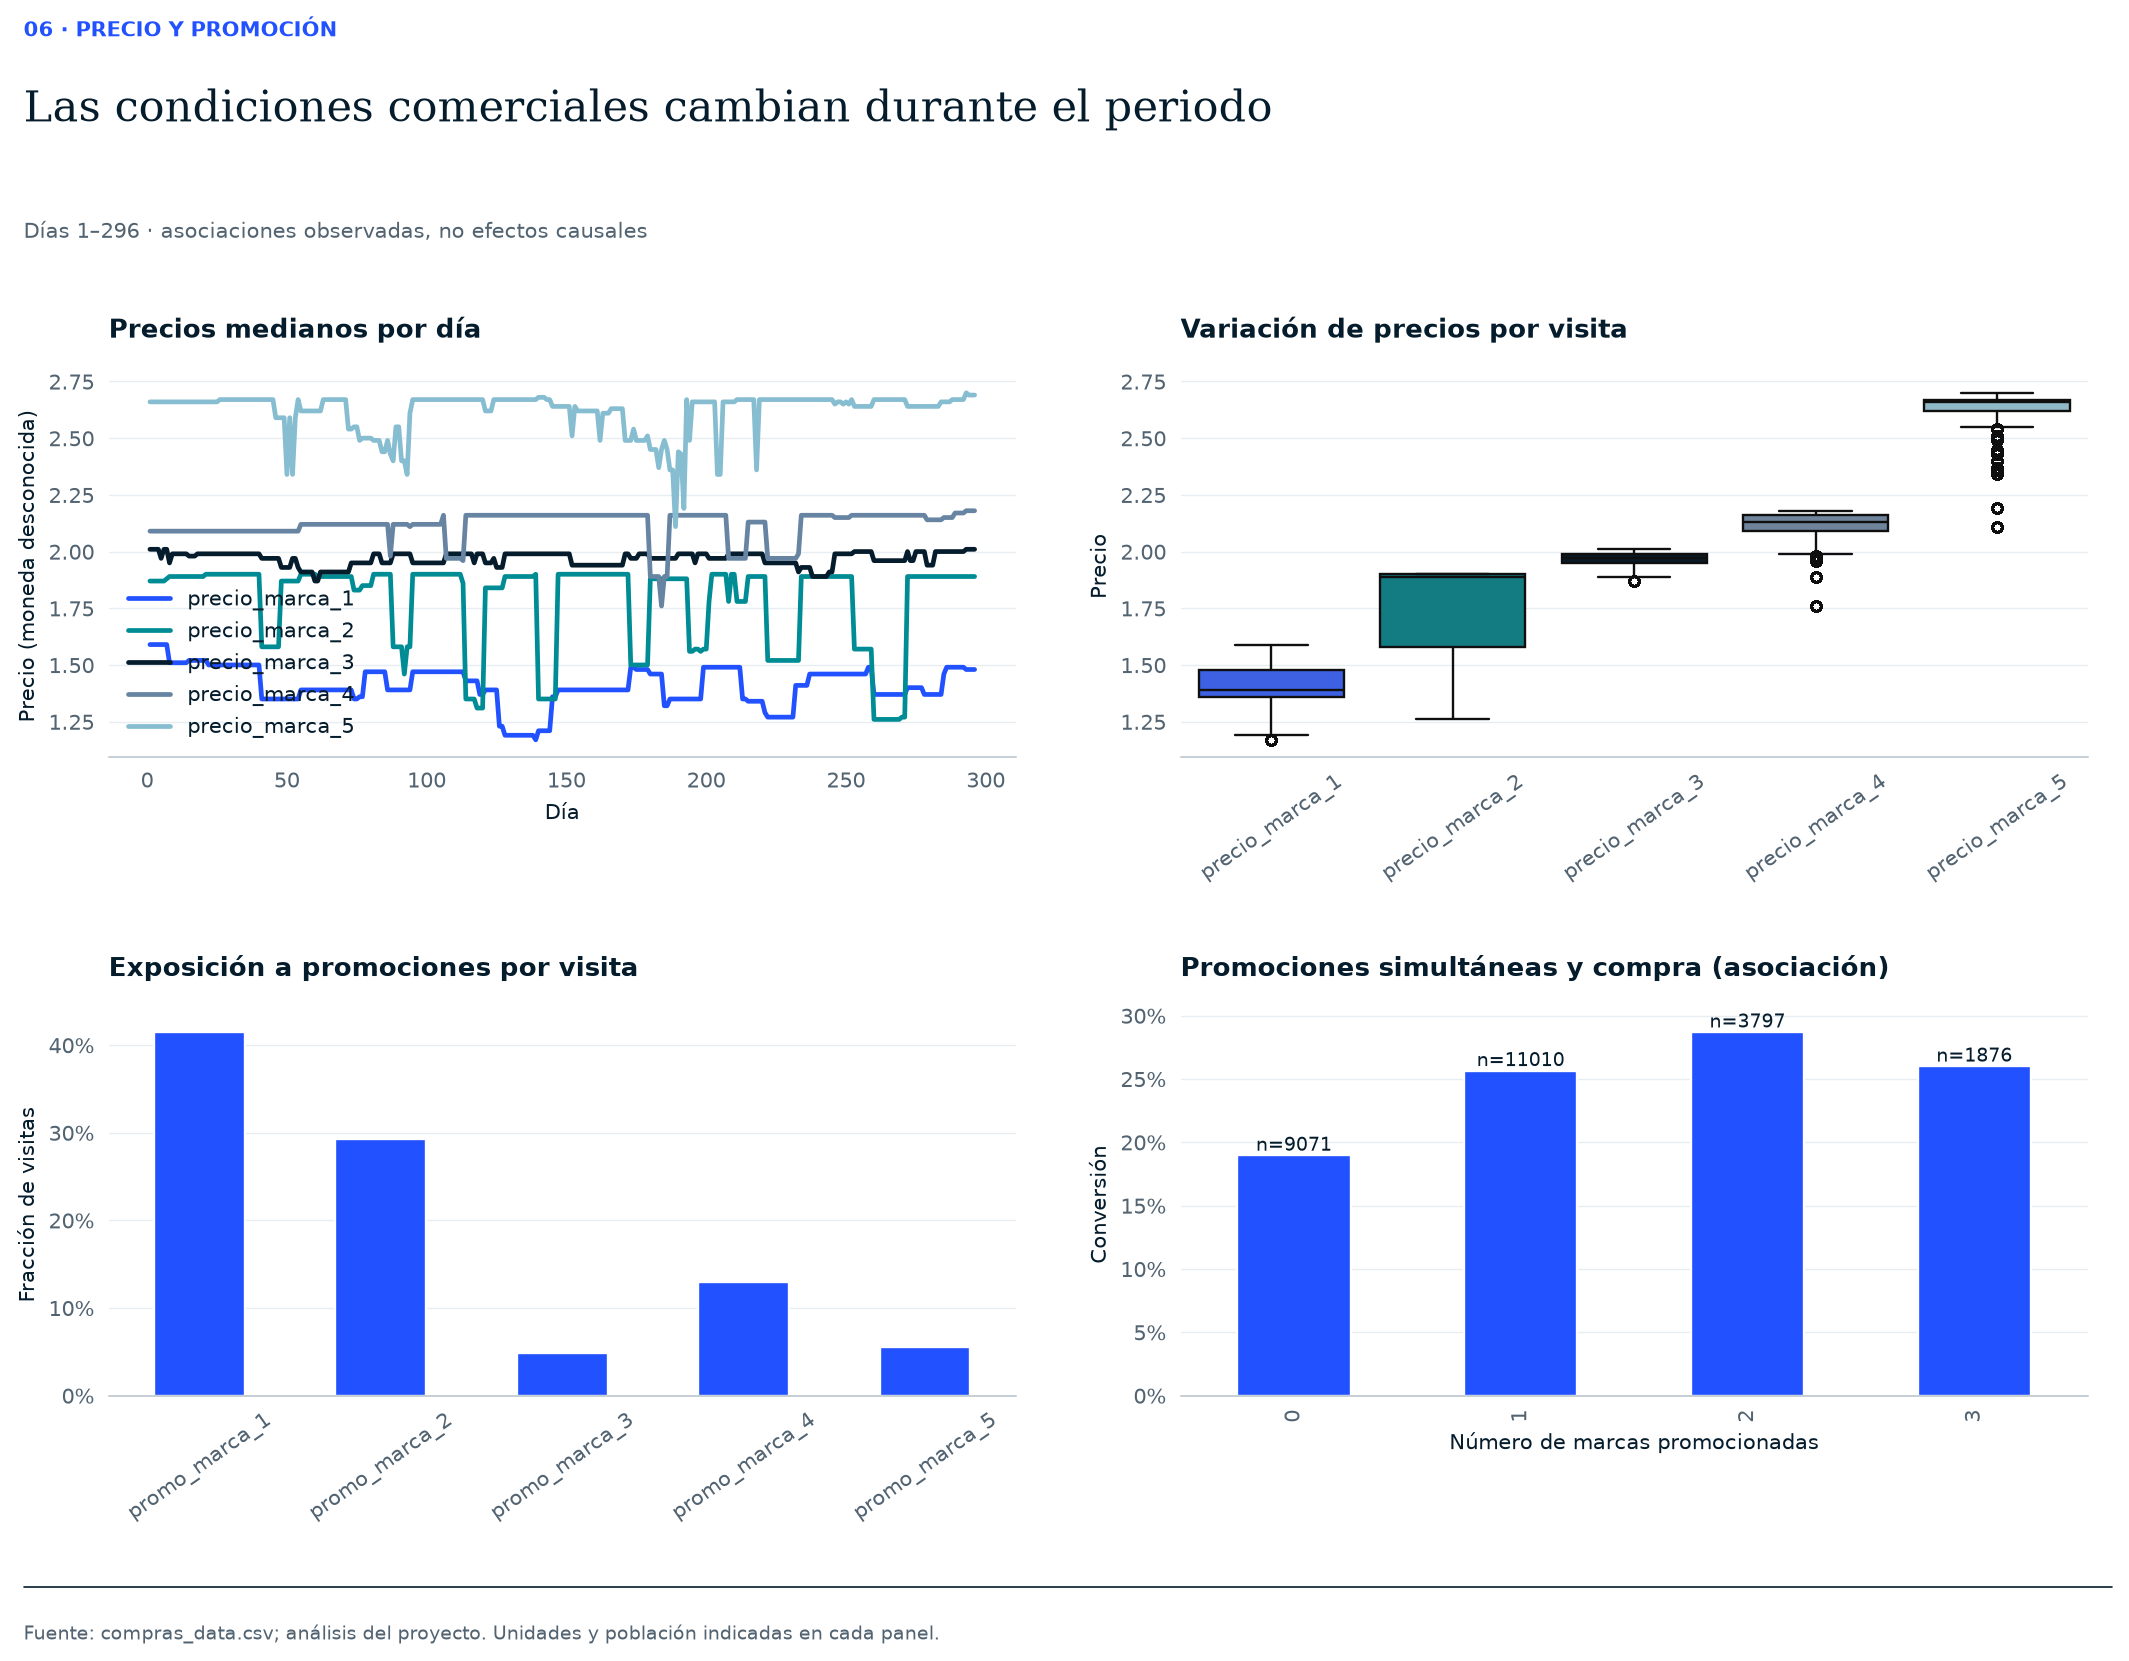

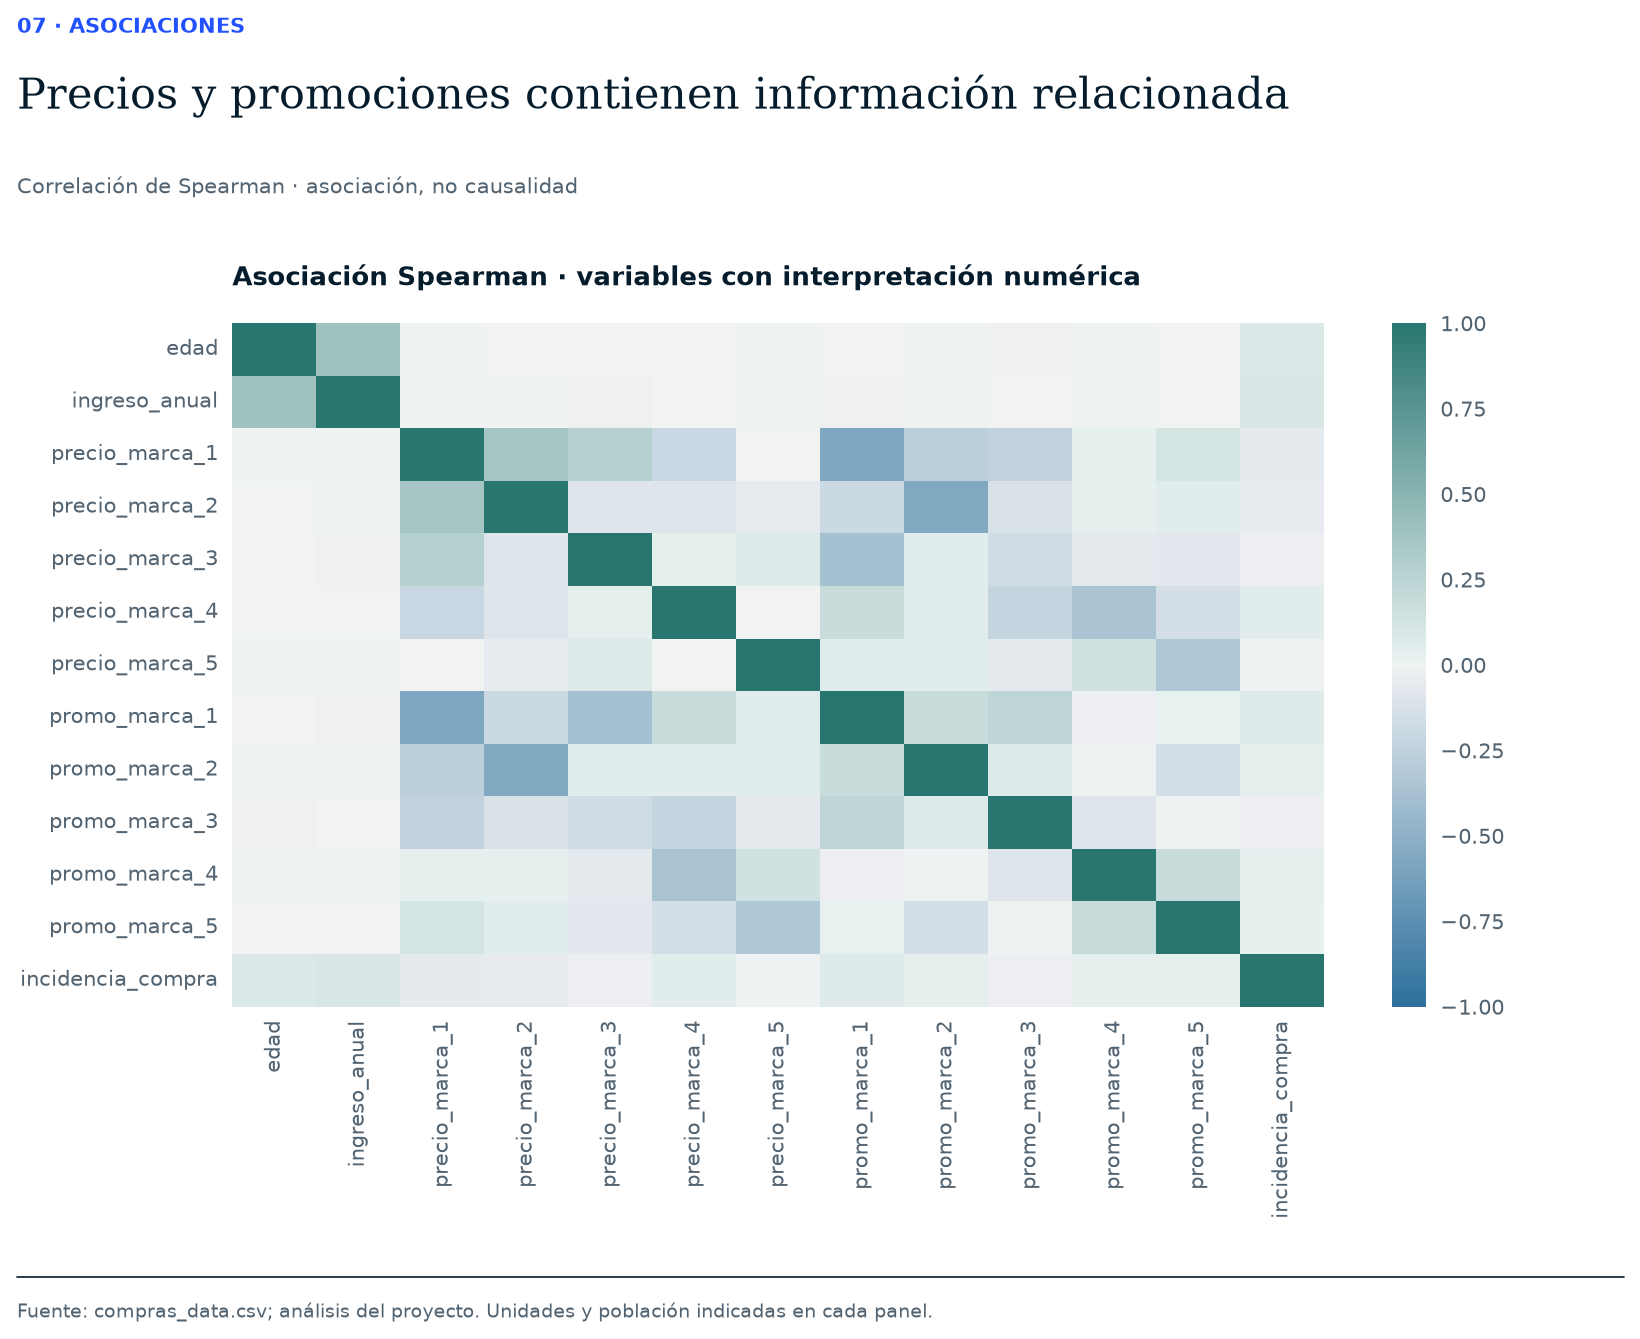

,max_precios_distintos_en_un_dia
precio_marca_1,1
precio_marca_2,1
precio_marca_3,1
precio_marca_4,1
precio_marca_5,1


In [7]:
display(Markdown("## 5 · ¿Cómo varían los precios y promociones?\n**Nivel: visita y día.** Buscamos diferencias y asociaciones, no efectos causales."))
display(Image(filename=str(OUTPUT / "figures/06_comercial.png")))
display(Image(filename=str(OUTPUT / "figures/07_asociaciones.png")))
price_consistency = (
    development.groupby("dia_visita")[[f"precio_marca_{i}" for i in range(1, 6)]]
    .nunique()
    .max()
)
display(style_table(price_consistency.to_frame("max_precios_distintos_en_un_dia")))

Los precios y promociones pueden estar relacionados con el periodo y el perfil de los visitantes. Las asociaciones observadas no permiten atribuir cambios de compra a una promoción.

## 6 · ¿Se relaciona el historial con la compra?
**Nivel: visita.** Comparamos la conversión y el número de visitas por recencia y frecuencia.

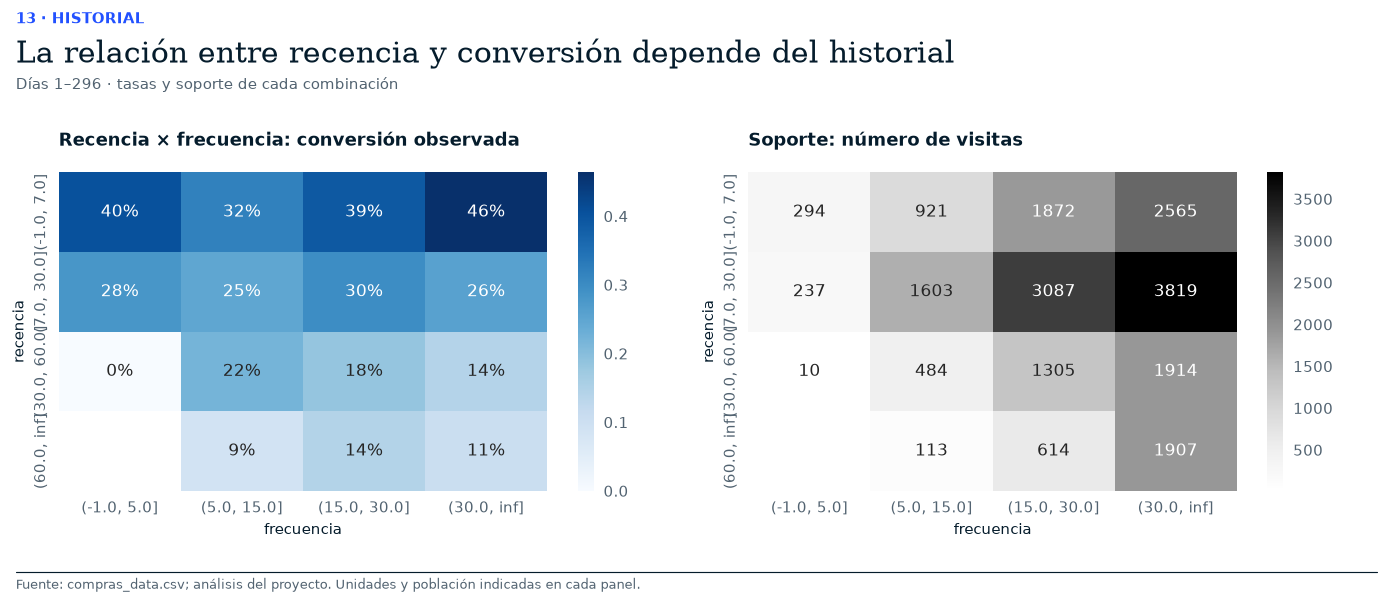

In [8]:
display(Markdown("## 6 · ¿Se relaciona el historial con la compra?\n**Nivel: visita.** Comparamos la conversión y el número de visitas por recencia y frecuencia."))
events, predictors = features(development)
interaction = (
    events.assign(
        recencia=pd.cut(events.dias_desde_compra, [-1, 7, 30, 60, np.inf]),
        frecuencia=pd.cut(events.visitas_previas, [-1, 5, 15, 30, np.inf]),
    )
    .groupby(["recencia", "frecuencia"], observed=True)
    .incidencia_compra.agg(["mean", "size"])
)
import seaborn as sns

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(
    interaction["mean"].unstack(), annot=True, fmt=".0%", cmap="Blues", ax=axes[0]
)
sns.heatmap(
    interaction["size"].unstack(), annot=True, fmt=".0f", cmap="Greys", ax=axes[1]
)
axes[0].set_title("Recencia × frecuencia: conversión observada")
axes[1].set_title("Soporte: número de visitas")
save(figure, OUTPUT / "figures", "13_interaccion", close=False)
plt.show()

## 7 · Hipótesis para contrastar

| Observación o pregunta | Siguiente paso |
|---|---|
| ¿Aporta el historial del cliente? | Evaluar frecuencia, recencia y compras previas. |
| ¿Aportan precios y promociones? | Comparar con un modelo sin variables comerciales. |
| ¿Aporta el perfil demográfico? | Comparar con un modelo sin demografía. |
| ¿Qué significan los históricos originales? | Usar eventos anteriores con definiciones explícitas. |

Las hipótesis se evalúan en ventanas posteriores. Las métricas existentes corresponden a los cortes anteriores y no se han recalculado para la propuesta 85/15.